# Linear SVM

Saurya Jonchhe

Same question as my logistic regression notebook, just a different model. How many phishing URLs does this linear SVM catch, and what does it get wrong? Phishing is 1, benign is 0. I report accuracy, phishing precision, recall, F1, and ROC AUC, and I also show the always-benign baseline.

Run the cells from the project folder.


In [1]:
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)
from dataset_preparation import prepare_datasets

print("scikit-learn version:", sklearn.__version__)
%matplotlib inline

scikit-learn version: 1.6.1


## Setup

Same prep as the other notebook. Duplicates are dropped, the split is the shared 60/20/20, and the scaler is fit on train only. Raw url, dom, and tld stay out of the model.

Only dev counts here. I am not touching test.


In [2]:
data = prepare_datasets()
pipeline = data["pipeline"]
X_train = pipeline.fit_transform(data["X_train"])
X_dev = pipeline.transform(data["X_dev"])
y_train = data["y_train"]
y_dev = data["y_dev"]
feature_names = pipeline.get_feature_names_out()

assert "label" not in feature_names
assert not any(name in feature_names for name in ("url", "dom", "tld"))
assert np.isfinite(X_train).all() and np.isfinite(X_dev).all()
assert set(data["X_train"]["url"]).isdisjoint(set(data["X_dev"]["url"]))

split_summary = pd.DataFrame({
    "Split": ["Train", "Dev"],
    "Rows": [len(y_train), len(y_dev)],
    "Phishing rows": [int(y_train.sum()), int(y_dev.sum())],
    "Phishing share": [y_train.mean(), y_dev.mean()],
})
display(split_summary.round(4))
print(f"Prepared numeric features: {len(feature_names)}")
print(f"Training shape: {X_train.shape}; dev shape: {X_dev.shape}")

,Split,Rows,Phishing rows,Phishing share
0,Train,69138,9954,0.144
1,Dev,23046,3318,0.144


Prepared numeric features: 22
Training shape: (69138, 22); dev shape: (23046, 22)


## Why these settings

This is a linear boundary with squared hinge loss and L2. C=1.0 and no class weight, which is different from Nipun's C=0.01 with balanced weights. dual=False just means it solves the primal form. I copied these from the README. LinearSVC has no probabilities, so ROC AUC uses the decision scores.

Again, this is the normal solver, not mini-batch gradient descent.


In [3]:
from sklearn.svm import LinearSVC

model = LinearSVC(
    penalty="l2",
    loss="squared_hinge",
    dual=False,
    C=1.0,
    class_weight=None,
    max_iter=5000,
    random_state=42,
)

## Fit

Same warning check as the logistic notebook. Convergence warnings are separate from the numerical ones. I recompute the decision scores feature by feature and stop if they disagree with the model.


In [4]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

convergence_warnings = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
print("Fit time (seconds):", round(fit_seconds, 3))
print("Solver iterations:", model.n_iter_)
print("Fit warnings:", sorted(set(str(w.message) for w in captured)) or "None")
assert not convergence_warnings, convergence_warnings

Fit time (seconds): 0.08
Solver iterations: 7
Fit warnings: None


In [5]:
def measure_split(X, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        predicted = model.predict(X)
        decision = model.decision_function(X)
        ranking = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else decision
    direct = np.einsum("ij,j->i", X, model.coef_[0]) + model.intercept_[0]
    assert np.isfinite(ranking).all() and np.isfinite(decision).all()
    assert np.allclose(decision, direct, rtol=1e-10, atol=1e-10)
    metrics = {
        "Accuracy": accuracy_score(y, predicted),
        "Phishing precision": precision_score(y, predicted, zero_division=0),
        "Phishing recall": recall_score(y, predicted, zero_division=0),
        "Phishing F1": f1_score(y, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(y, ranking),
    }
    return metrics, predicted, ranking, sorted(set(str(w.message) for w in caught))

train_metrics, _, _, train_warnings = measure_split(X_train, y_train)
dev_metrics, dev_predictions, dev_scores, dev_warnings = measure_split(X_dev, y_dev)
metrics = pd.DataFrame({"Train": train_metrics, "Dev": dev_metrics})
display(metrics.round(4))
print("Numerical warnings:", sorted(set(train_warnings + dev_warnings)) or "None")
print("Independent decision-score checks passed for both splits.")
print(f"Always-benign dev baseline: accuracy={1 - y_dev.mean():.4f}, phishing recall=0, F1=0, AUC=0.5")

,Train,Dev
Accuracy,0.9525,0.9511
Phishing precision,0.9173,0.9170
Phishing recall,0.7368,0.7260
Phishing F1,0.8172,0.8104
ROC AUC,0.9749,0.9760


Numerical warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']
Independent decision-score checks passed for both splits.
Always-benign dev baseline: accuracy=0.8560, phishing recall=0, F1=0, AUC=0.5


## Where it goes wrong

Confusion matrix rows are the real labels. Bottom left is missed phishing, top right is false alarms. The ROC curve is the ranking, not just the default cutoff. I did not move the threshold.


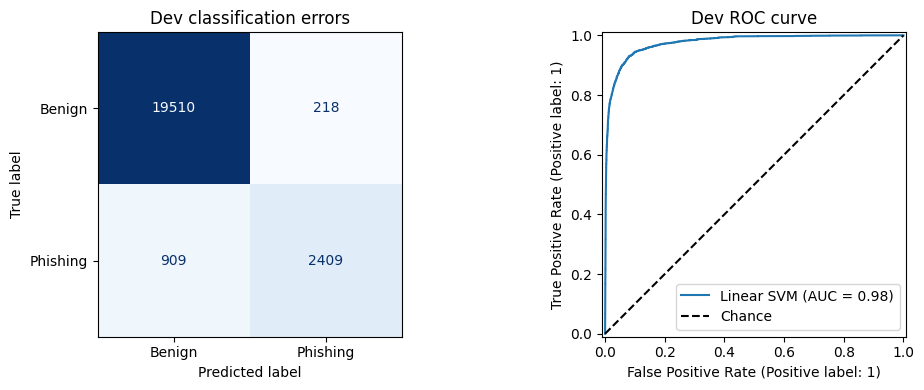

,Dev counts
Correct benign,19510
False alarms,218
Missed phishing,909
Caught phishing,2409


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_dev, dev_predictions, labels=[0, 1], display_labels=["Benign", "Phishing"],
    values_format="d", cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Dev classification errors")
RocCurveDisplay.from_predictions(y_dev, dev_scores, name="Linear SVM", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set_title("Dev ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_dev, dev_predictions, labels=[0, 1]).ravel()
display(pd.Series({"Correct benign": tn, "False alarms": fp, "Missed phishing": fn, "Caught phishing": tp}, name="Dev counts").to_frame())

## What I got


In [7]:
display(Markdown(
    f"On dev this gets {dev_metrics['Accuracy']:.2%} accuracy, "
    f"{dev_metrics['Phishing precision']:.2%} phishing precision, "
    f"{dev_metrics['Phishing recall']:.2%} recall, "
    f"F1 {dev_metrics['Phishing F1']:.4f}, and ROC AUC {dev_metrics['ROC AUC']:.4f}. "
    f"It misses {fn:,} phishing URLs and flags {fp:,} benign ones. "
    f"Train F1 is {train_metrics['Phishing F1']:.4f}, so the gap is only "
    f"{train_metrics['Phishing F1'] - dev_metrics['Phishing F1']:.4f}. "
    "Train and dev are close. I still have not looked at test."
))

On dev this gets 95.11% accuracy, 91.70% phishing precision, 72.60% recall, F1 0.8104, and ROC AUC 0.9760. It misses 909 phishing URLs and flags 218 benign ones. Train F1 is 0.8172, so the gap is only 0.0068. Train and dev are close. I still have not looked at test.

This SVM is picky. When it flags a URL it is usually right, but it misses a lot of phishing ones. Dev F1 is 0.8104 and recall is 0.7260.

Next to my L1 logistic regression, the SVM has the better F1 (0.8104 vs 0.7795) and the worse recall (0.7260 vs 0.9222). If we care more about F1, this is the stronger of my two. If we care more about catching phishing URLs, the logistic one is better.

Test has not been scored.
